In [ ]:
import numpy as np
import tensorflow.keras as keras
import matplotlib.pyplot as plt
from tensorflow import (
    shape as tf_shape,
    exp as tf_exp
)
from tensorflow.random import normal as tf_normal

In [ ]:
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

x_train = x_train.astype(np.float32) / 255
x_test = x_test.astype(np.float32) / 255

print("Traning Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Traning Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


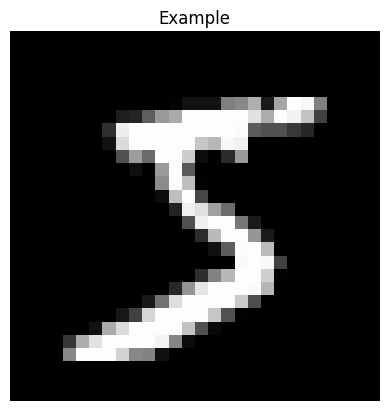

In [ ]:
plt.imshow(x_train[0], cmap='gray')
plt.title("Example")
plt.axis('off')
plt.show()

# Generic AutoEncoder

In [ ]:
x_train.shape = len(x_train), 28*28
x_test.shape = len(x_test), 28*28

print("Traning Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

Traning Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)


In [ ]:
input_img_layer = keras.layers.Input(shape=(784, ))

x = keras.layers.Dense(256, activation='relu')(input_img_layer)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dense(64, activation='relu', name='latent')(x)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dense(256, activation='relu')(x)
output_img_layer = keras.layers.Dense(784, activation='sigmoid')(x)

deep_ae = keras.Model(input_img_layer, output_img_layer)
deep_ae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)
deep_ae.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 484,944 (1.85 MB)

 Trainable params: 484,944 (1.85 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = deep_ae.fit(
    x_train, x_train,
    epochs = 15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0920 - val_loss: 0.0904
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0895 - val_loss: 0.0876
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0876 - val_loss: 0.0856
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - loss: 0.0858 - val_loss: 0.0842
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.0843 - val_loss: 0.0832
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0832 - val_loss: 0.0819
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.0821 - val_loss: 0.0815
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - loss: 0.0814 - val_loss: 0.0803
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.0805 - val_loss: 0.0803
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0798 - val_loss: 0.0793
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.0792 - val_loss: 0.0788
Epoch 12/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


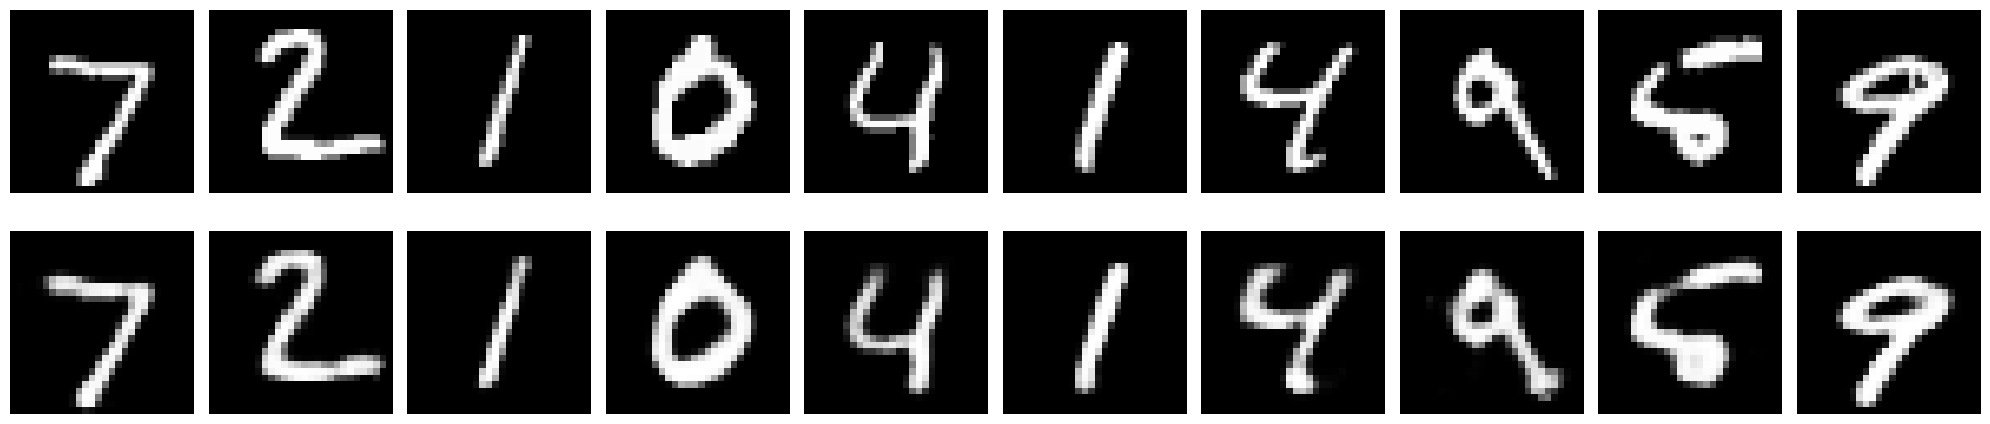

In [ ]:
decoded_imgs = deep_ae.predict(x_test[:10])

plt.figure(figsize=(20, 5))
for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 10, 10+i+1)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Sparse Auto Encoder

In [ ]:
input_img_layer = keras.layers.Input(shape=(784, ))

x = keras.layers.Dense(
    units=256,
    activation='relu',
    activity_regularizer=keras.regularizers.l1(1e-4)
)(input_img_layer)
x = keras.layers.Dense(
    units=128,
    activation='relu',
    activity_regularizer=keras.regularizers.l1(1e-4)
)(x)
x = keras.layers.Dense(
    units=64,
    activation='relu',
    name='latent',
    activity_regularizer=keras.regularizers.l1(1e-4)
)(x)
x = keras.layers.Dense(
    units=128,
    activation='relu',
    activity_regularizer=keras.regularizers.l1(1e-4)
)(x)
x = keras.layers.Dense(
    units=256,
    activation='relu',
    activity_regularizer=keras.regularizers.l1(1e-4)
)(x)
output_img_layer = keras.layers.Dense(784, activation='sigmoid')(x)

sparse_ae = keras.Model(input_img_layer, output_img_layer)
sparse_ae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)
sparse_ae.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 484,944 (1.85 MB)

 Trainable params: 484,944 (1.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - loss: 0.6815 - val_loss: 0.6155
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.5832 - val_loss: 0.5535
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.5275 - val_loss: 0.5038
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.4827 - val_loss: 0.4638
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.4466 - val_loss: 0.4314
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.4174 - val_loss: 0.4050
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.3935 - val_loss: 0.3834
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.3739 - val_loss: 0.3656
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - loss: 0.3577 - val_loss: 0.3508
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.3442 - val_loss: 0.3385
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - loss: 0.3329 - val_loss: 0.3282
Epoch 12/15
235/235 ━━━━━━━━━━━━━━━━━━━

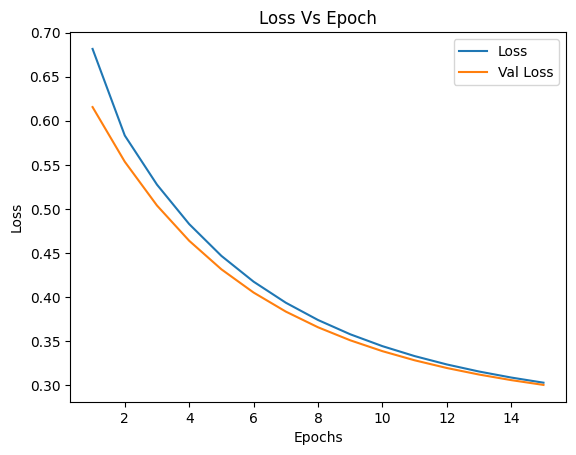

In [ ]:
history = sparse_ae.fit(
    x_train, x_train,
    epochs = 15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

plt.plot(range(1, 16), history.history['loss'], label='Loss')
plt.plot(range(1, 16), history.history['val_loss'], label='Val Loss')
plt.title("Loss Vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


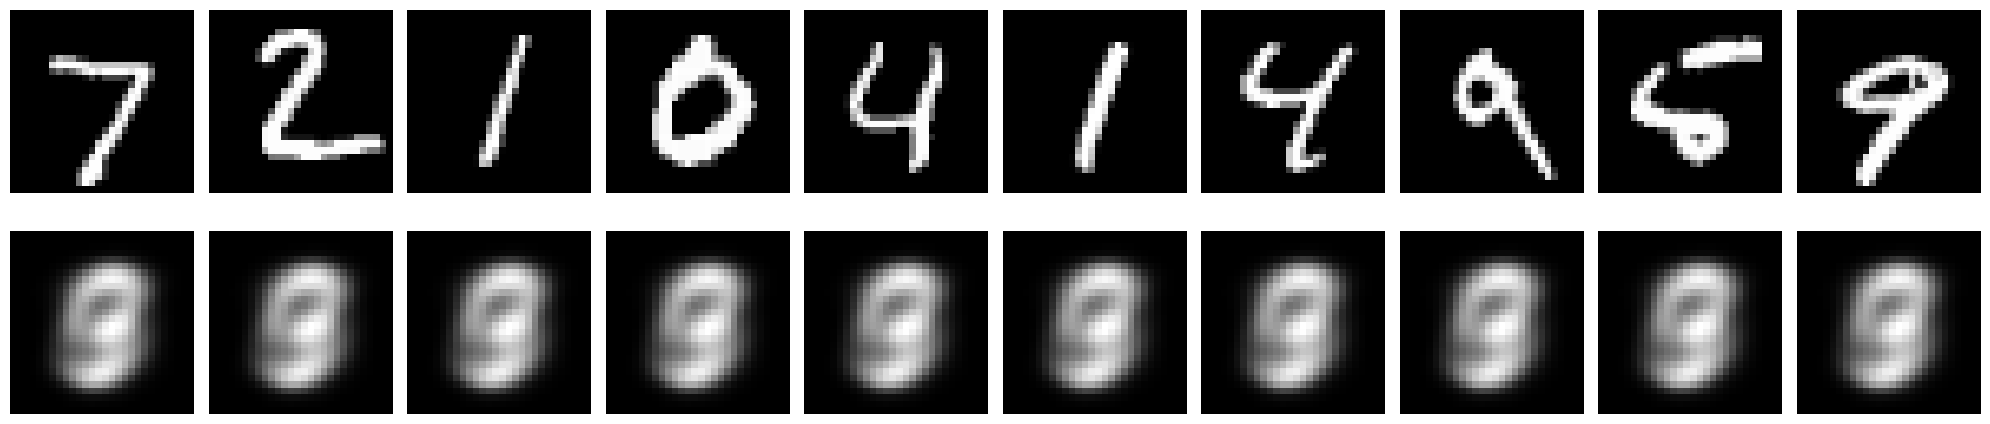

In [ ]:
decoded_imgs = sparse_ae.predict(x_test[:10])

plt.figure(figsize=(20, 5))
for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 10, 10+i+1)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Denoising AutoEncoder

In [ ]:
NOISE_FACTOR = 0.5

x_train_noisy = x_train + NOISE_FACTOR * np.random.normal(
    loc=0,
    scale=1,
    size=x_train.shape
)

x_test_noisy = x_test + NOISE_FACTOR * np.random.normal(
    loc=0,
    scale=1,
    size=x_test.shape
)

x_train_noisy = x_train_noisy.clip(0, 1)
x_test_noisy = x_test_noisy.clip(0, 1)

In [ ]:
input_img_layer = keras.layers.Input(shape=(784, ))

x = keras.layers.Dense(256, activation='relu')(input_img_layer)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dense(64, activation='relu', name='latent')(x)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dense(256, activation='relu')(x)
output_img_layer = keras.layers.Dense(784, activation='sigmoid')(x)

denoise_ae = keras.Model(input_img_layer, output_img_layer)
denoise_ae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)
denoise_ae.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 484,944 (1.85 MB)

 Trainable params: 484,944 (1.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.2429 - val_loss: 0.1805
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.1648 - val_loss: 0.1529
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - loss: 0.1478 - val_loss: 0.1415
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.1391 - val_loss: 0.1353
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.1332 - val_loss: 0.1307
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - loss: 0.1287 - val_loss: 0.1267
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - loss: 0.1252 - val_loss: 0.1238
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.1226 - val_loss: 0.1217
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 0.1204 - val_loss: 0.1206
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.1188 - val_loss: 0.1191
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - loss: 0.1173 - val_loss: 0.1177
Epoch 12/15
235/235 ━━━━━━━━━━━━━━━━

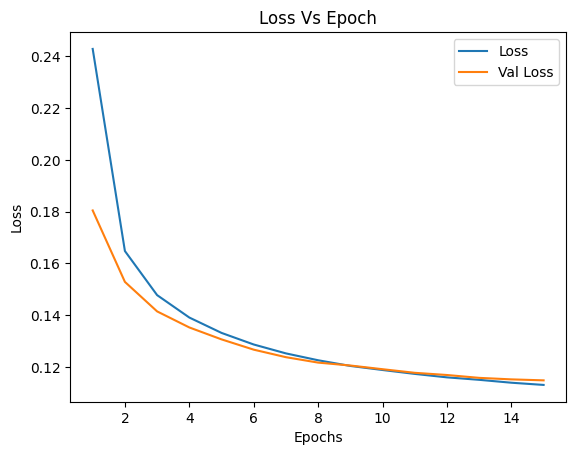

In [ ]:
history = denoise_ae.fit(
    x_train_noisy, x_train,
    epochs = 15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

plt.plot(range(1, 16), history.history['loss'], label='Loss')
plt.plot(range(1, 16), history.history['val_loss'], label='Val Loss')
plt.title("Loss Vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step


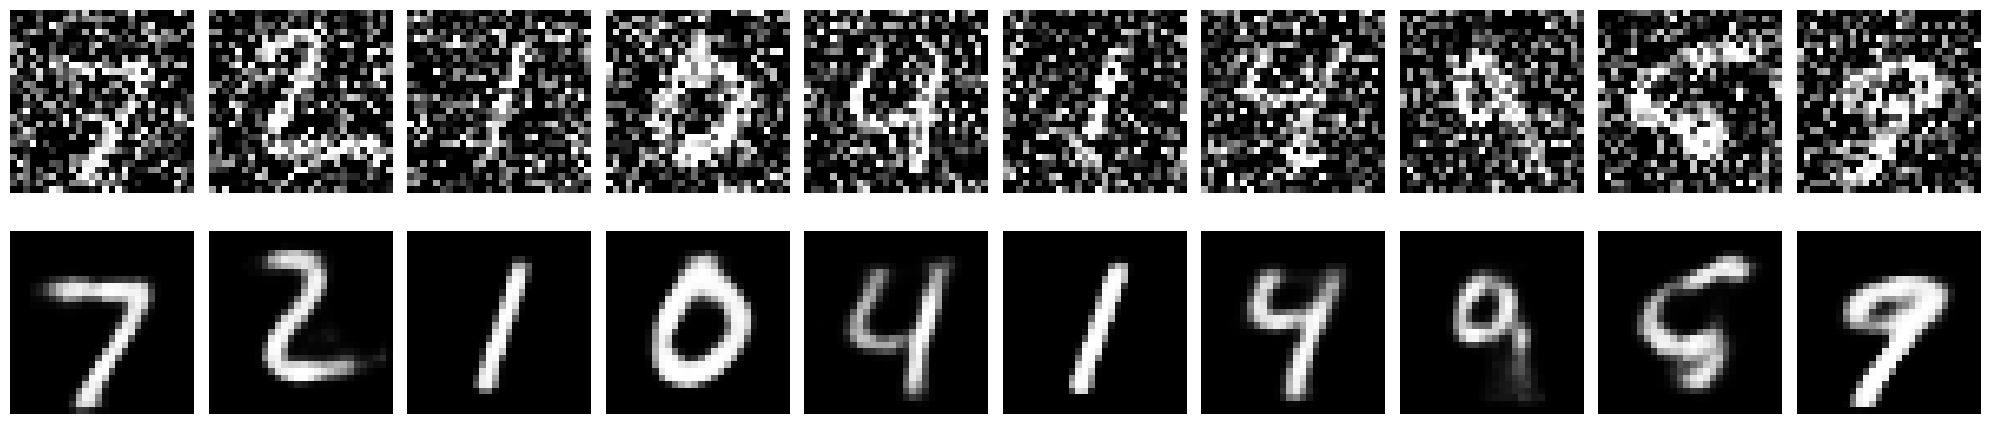

In [ ]:
decoded_imgs = denoise_ae.predict(x_test[:10])

plt.figure(figsize=(20, 5))
for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 10, 10+i+1)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

# CNN Based Denoising AutoEncoder

In [ ]:
NOISE_FACTOR = 0.5

x_train_noisy = x_train + NOISE_FACTOR * np.random.normal(
    loc=0,
    scale=1,
    size=x_train.shape
)

x_test_noisy = x_test + NOISE_FACTOR * np.random.normal(
    loc=0,
    scale=1,
    size=x_test.shape
)

x_train_noisy = x_train_noisy.clip(0, 1)
x_test_noisy = x_test_noisy.clip(0, 1)

In [ ]:
input_img_layer = keras.layers.Input(shape=(28, 28, 1))

x = keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(input_img_layer)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), padding='same')(x)

x = keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), padding='same')(x)

latent = keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding='same',
    activation='relu',
    name='latent'
)(x)

x = keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(latent)
x = keras.layers.UpSampling2D(size=(2, 2))(x)

x = keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(x)
x = keras.layers.UpSampling2D(size=(2, 2))(x)

output_img_layer = keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    padding='same',
    activation='sigmoid'
)(x)

denoise_ae = keras.Model(input_img_layer, output_img_layer)
denoise_ae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

denoise_ae.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,425 (435.25 KB)

 Trainable params: 111,425 (435.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - loss: 0.1864 - val_loss: 0.1176
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1130 - val_loss: 0.1075
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1067 - val_loss: 0.1041
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1039 - val_loss: 0.1020
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.1022 - val_loss: 0.1003
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.1008 - val_loss: 0.0993
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0997 - val_loss: 0.0986
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0988 - val_loss: 0.0986
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0982 - val_loss: 0.0973
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0975 - val_loss: 0.0972
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0969 - val_loss: 0.0978
Epoch 12/15
235/235 ━━━━━━━━━━━━━━━━━━━━

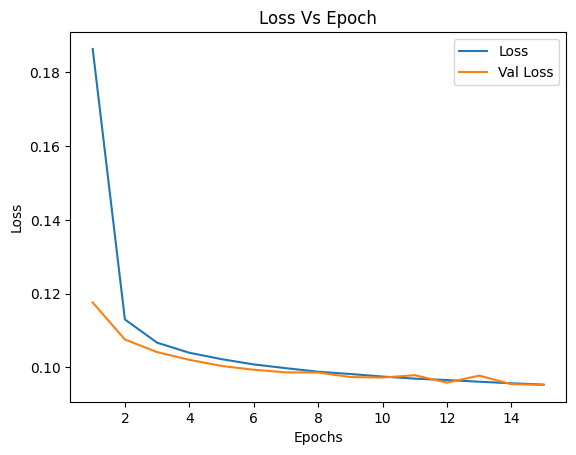

In [ ]:
history = denoise_ae.fit(
    x_train_noisy, x_train,
    epochs = 15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

plt.plot(range(1, 16), history.history['loss'], label='Loss')
plt.plot(range(1, 16), history.history['val_loss'], label='Val Loss')
plt.title("Loss Vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 916ms/step


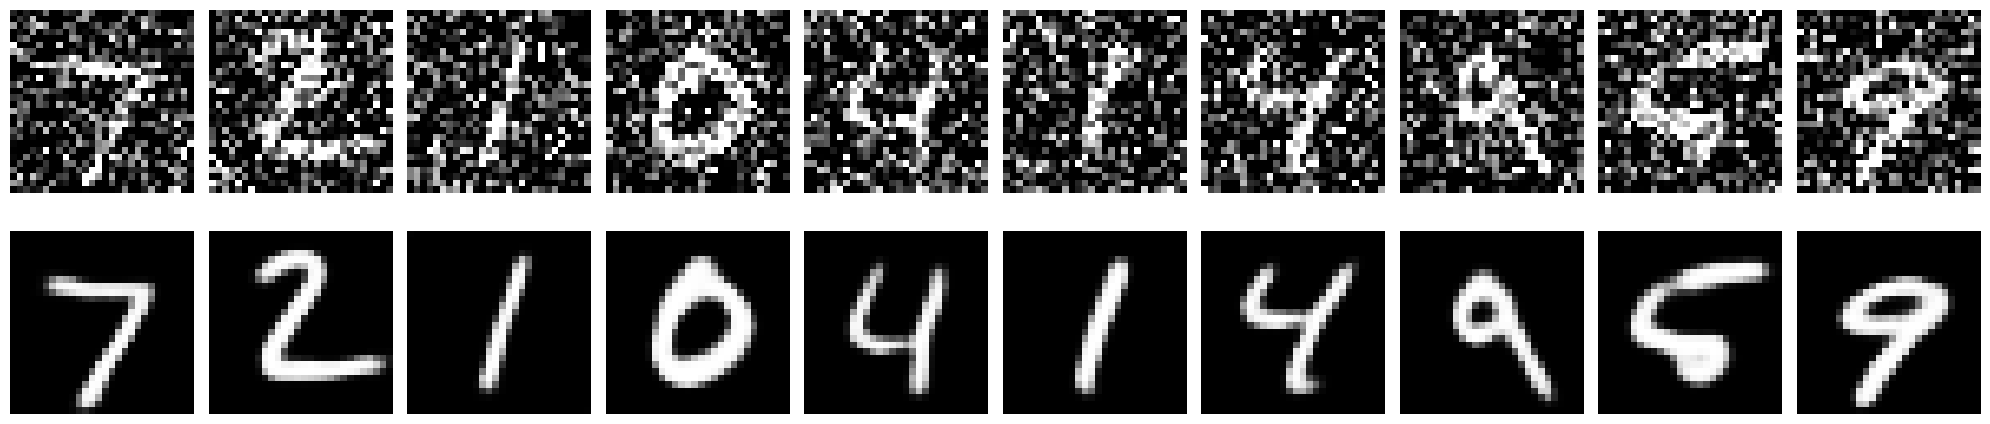

In [ ]:
decoded_imgs = denoise_ae.predict(x_test[:10])

plt.figure(figsize=(20, 5))
for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 10, 10+i+1)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Iterative Denoising Experiments

||Spoiler Alert: Failed!||

In [ ]:
input_img_layer = keras.layers.Input(shape=(28, 28, 1))

x = keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(input_img_layer)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), padding='same')(x)

x = keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), padding='same')(x)

latent = keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding='same',
    activation='relu',
    name='latent'
)(x)

x = keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(latent)
x = keras.layers.UpSampling2D(size=(2, 2))(x)

x = keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    padding='same',
    activation='relu'
)(x)
x = keras.layers.UpSampling2D(size=(2, 2))(x)

output_img_layer = keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    padding='same',
    activation='sigmoid'
)(x)

denoise_ae = keras.Model(input_img_layer, output_img_layer)
denoise_ae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

denoise_ae.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,425 (435.25 KB)

 Trainable params: 111,425 (435.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
models = []
ITERS = 20
for i in range(ITERS):
    new_model = keras.models.clone_model(denoise_ae)
    new_model.compile(
        optimizer='adam',
        loss='binary_crossentropy'
    )
    models.append(new_model)

models

[<Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>,
 <Functional name=functional_2, built=True>]

In [ ]:
for i in range(ITERS):
    noise_more = (i + 1) / float(ITERS)
    noise_less = i / float(ITERS)

    x_train_noisy_more = np.clip(
        x_train + noise_more * np.random.normal(loc=0, scale=1, size=x_train.shape),
        0, 1
    )
    x_test_noisy_more = np.clip(
        x_test + noise_more * np.random.normal(loc=0, scale=1, size=x_test.shape),
        0, 1
    )

    x_train_noisy_less = np.clip(
        x_train + noise_less * np.random.normal(loc=0, scale=1, size=x_train.shape),
        0, 1
    )
    x_test_noisy_less = np.clip(
        x_test + noise_less * np.random.normal(loc=0, scale=1, size=x_test.shape),
        0, 1
    )

    print("=" * 25)
    print("ITERATION COUNT =>", i)
    print("=" * 25)

    models[i].fit(
        x_train_noisy_more, x_train_noisy_less,
        epochs=15,
        batch_size=256,
        shuffle=True,
        validation_data=(x_test_noisy_more, x_test_noisy_less)
    )

ITERATION COUNT => 0
Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - loss: 0.1376 - val_loss: 0.0814
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0785 - val_loss: 0.0744
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0740 - val_loss: 0.0719
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0718 - val_loss: 0.0706
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0705 - val_loss: 0.0694
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0695 - val_loss: 0.0685
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0688 - val_loss: 0.0681
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0683 - val_loss: 0.0675
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0679 - val_loss: 0.0680
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0675 - val_loss: 0.0671
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0672 - val_loss: 0.0666
Epoch 12/15
235/235

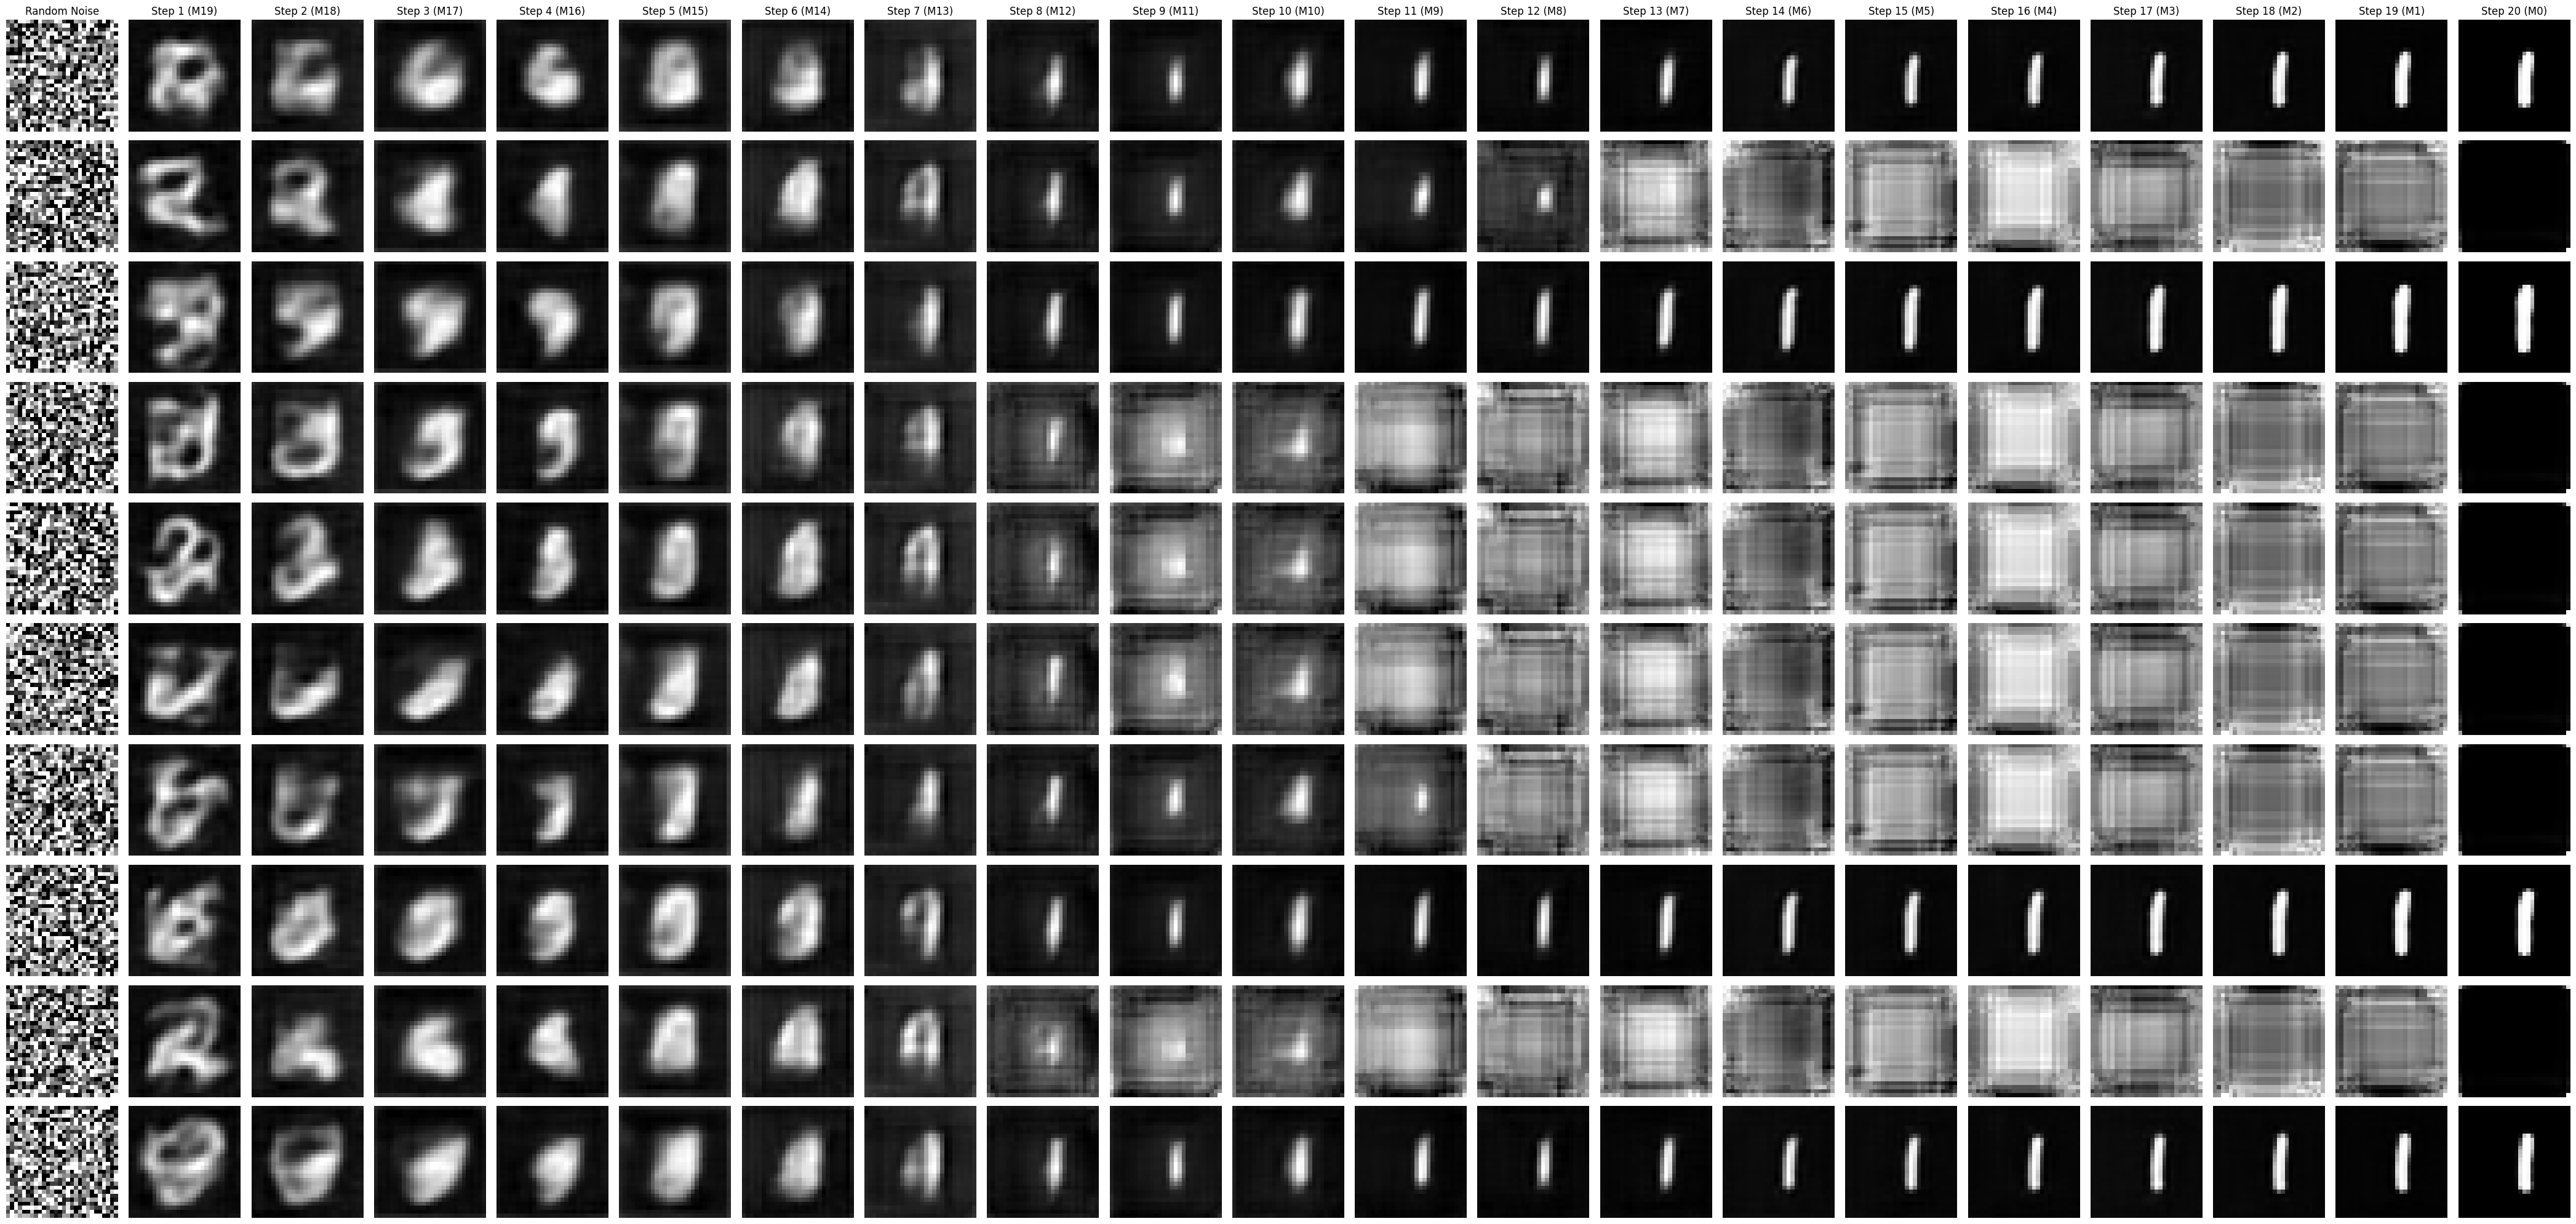

In [ ]:
num_samples = 10
fig, axes = plt.subplots(num_samples, ITERS + 1, figsize=(2 * (ITERS + 1), 2 * num_samples))

for row in range(num_samples):
    current_img = np.random.normal(loc=0.5, scale=0.5, size=(1, 28, 28, 1))
    current_img = np.clip(current_img, 0, 1)

    axes[row, 0].imshow(current_img.squeeze(), cmap='gray')
    axes[row, 0].axis('off')
    if row == 0:
        axes[row, 0].set_title('Random Noise')

    for col in range(ITERS):
        model_idx = (ITERS - 1) - col
        pred = models[model_idx].predict(current_img, verbose=0)
        current_img = pred

        axes[row, col + 1].imshow(current_img.squeeze(), cmap='gray')
        axes[row, col + 1].axis('off')
        if row == 0:
            axes[row, col + 1].set_title(f'Step {col + 1} (M{model_idx})')

plt.tight_layout()
plt.show()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
STAGE 0: PRE-TRAINING (Finding Base Low-Noise Convergence)
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - loss: 0.1443 - val_loss: 0.0804
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0751 - val_loss: 0.0717
Pre-training converged at epoch 2 with val_loss: 0.0717
CURRICULUM NOISE LEVEL: 0.05
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0716 - val_loss: 0.0699
Loss threshold reached (0.0699 < 0.09). Stepping noise.
CURRICULUM NOISE LEVEL: 0.10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0715 - val_loss: 0.0699
Loss threshold reached (0.0699 < 0.09). Stepping noise.
CURRICULUM NOISE LEVEL: 0.15
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0723 - val_loss: 0.0711
Loss threshold reached (0.0711 < 0.09). Stepping noise.
CURRICULUM NOISE LEVEL: 0.20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0740 - val_loss: 0.0731
Loss threshold reached (0.0731 < 0.09). Stepping noise.
CURRICULUM NOISE LEVEL: 0.25
235/235 

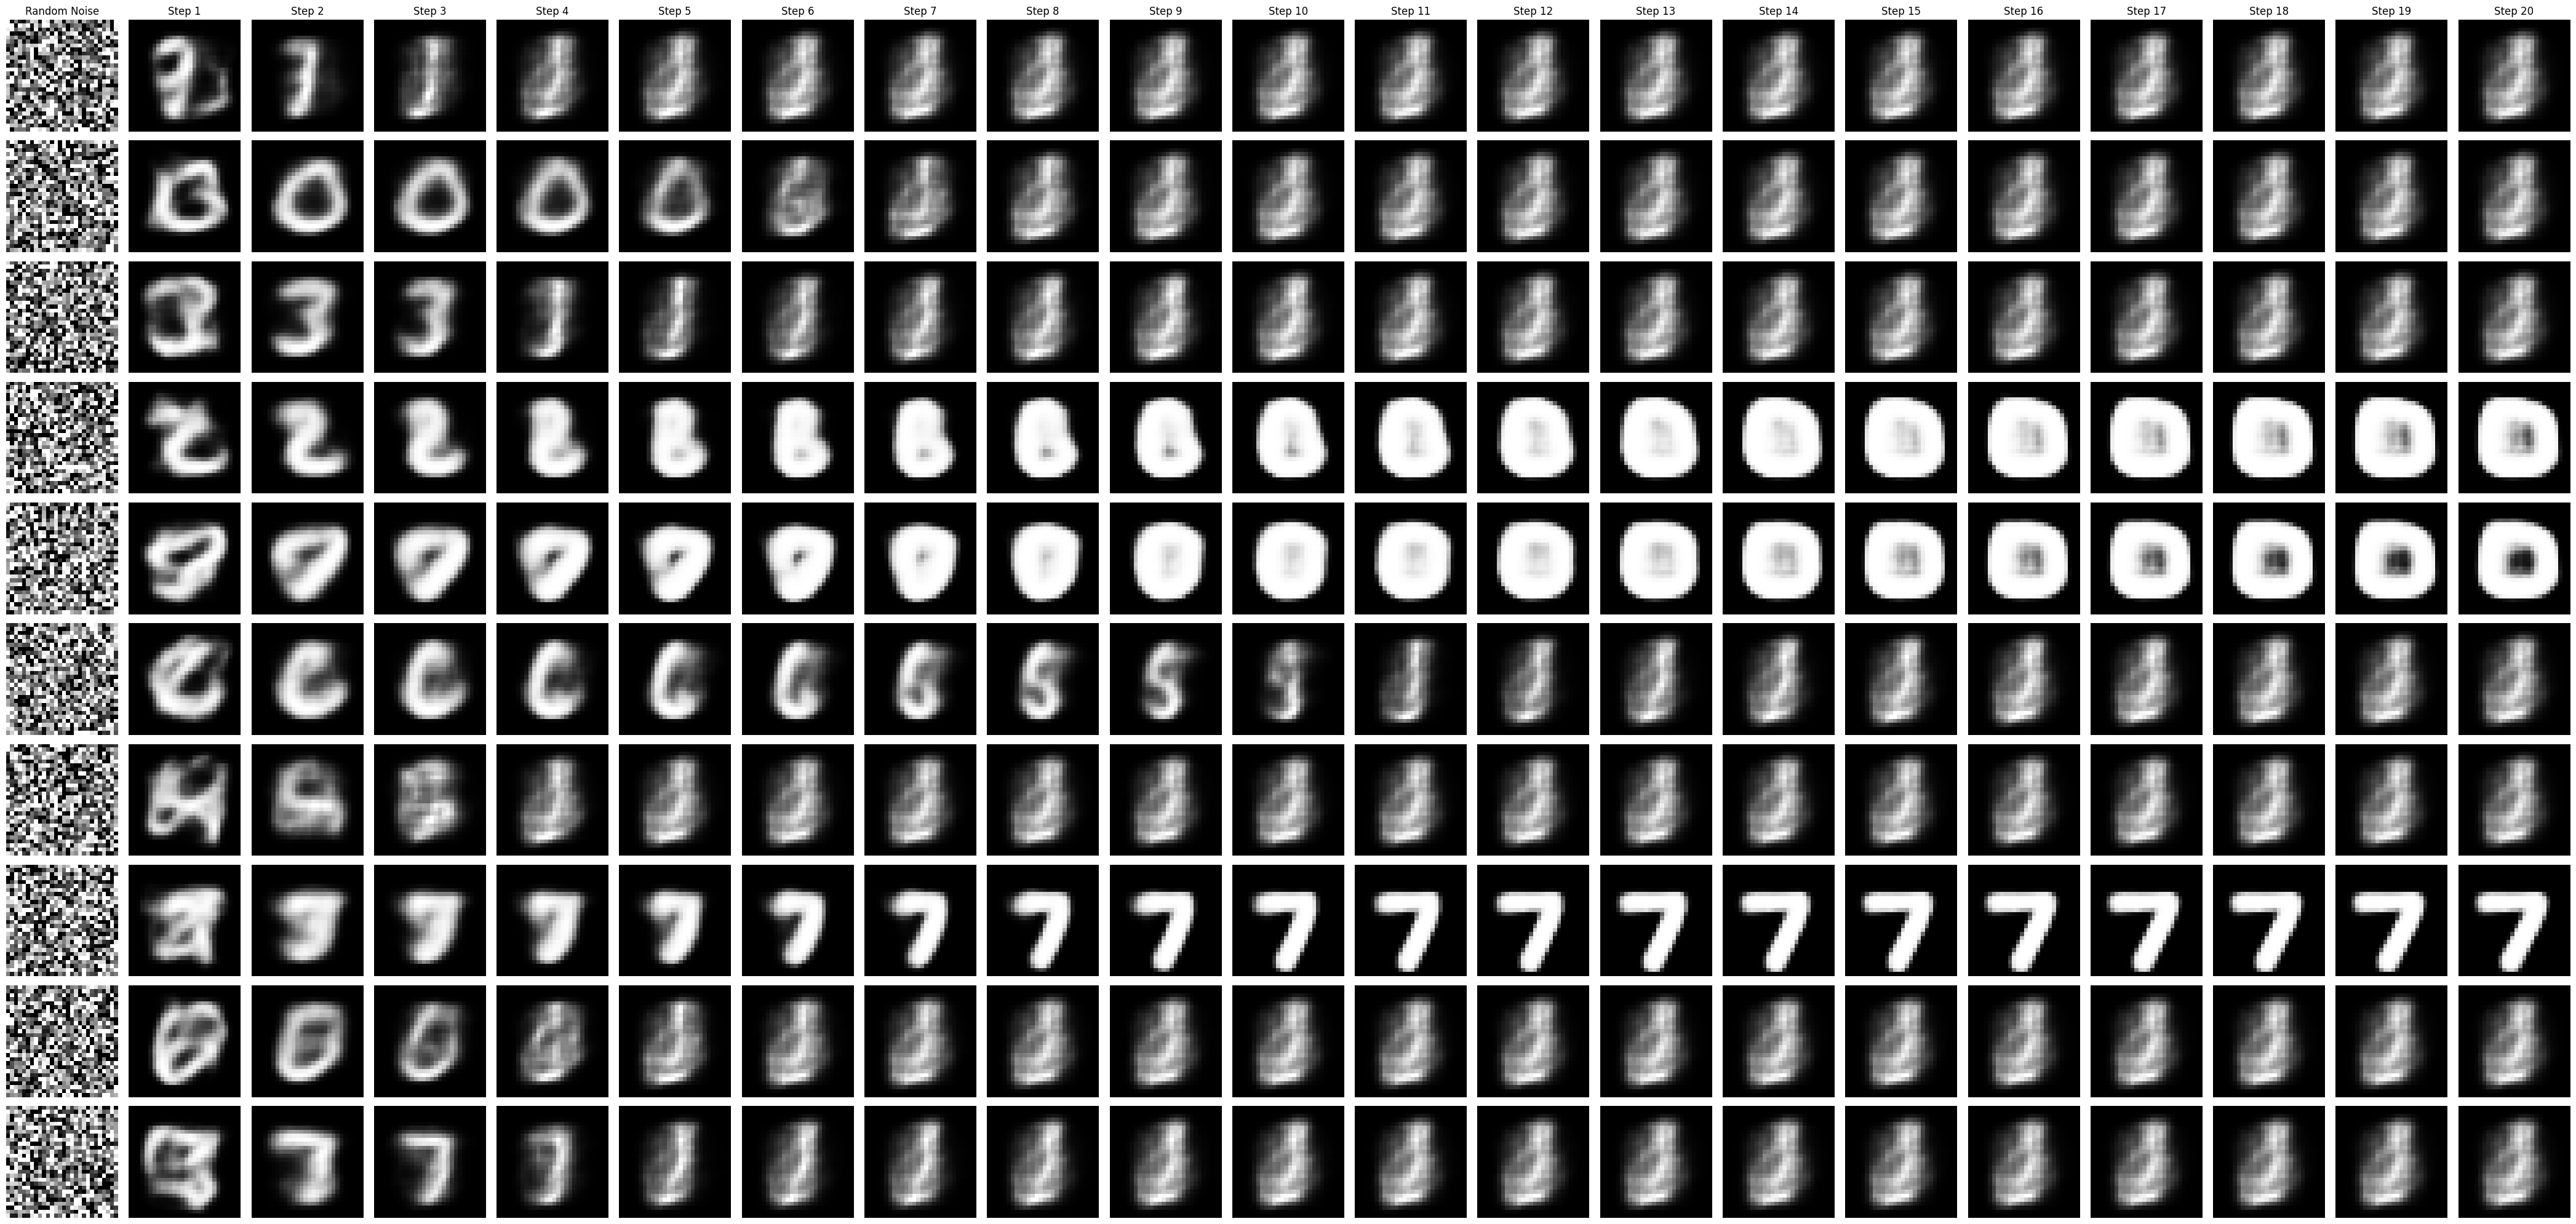

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import keras

input_img_layer = keras.layers.Input(shape=(28, 28, 1))

x = keras.layers.Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu')(input_img_layer)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), padding='same')(x)

x = keras.layers.Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu')(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), padding='same')(x)

x = keras.layers.Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='relu')(x)
x = keras.layers.Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='relu')(x)

x = keras.layers.Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu')(x)
x = keras.layers.UpSampling2D(size=(2, 2))(x)

x = keras.layers.Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu')(x)
x = keras.layers.UpSampling2D(size=(2, 2))(x)

output_img_layer = keras.layers.Conv2D(filters=1, kernel_size=(3, 3), padding='same', activation='sigmoid')(x)

iter_denoise_ae = keras.Model(input_img_layer, output_img_layer)
iter_denoise_ae.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy'
)

(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
x_test = x_test.astype('float32') / 255.0
x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))

noise_step = 0.05
ITERS = int(1.0 / noise_step)

print("=" * 45)
print("STAGE 0: PRE-TRAINING (Finding Base Low-Noise Convergence)")
print("=" * 45)

base_noise = 0.02
pretrain_threshold = 0.075
pretrain_converged = False

for epoch in range(20):
    x_train_noisy = np.clip(
        x_train + base_noise * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape),
        0.0, 1.0
    )
    x_test_noisy = np.clip(
        x_test + base_noise * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape),
        0.0, 1.0
    )

    history = iter_denoise_ae.fit(
        x_train_noisy, x_train,
        epochs=1,
        batch_size=256,
        shuffle=True,
        validation_data=(x_test_noisy, x_test),
        verbose=1
    )

    if history.history['val_loss'][0] < pretrain_threshold:
        print(f"Pre-training converged at epoch {epoch+1} with val_loss: {history.history['val_loss'][0]:.4f}")
        pretrain_converged = True
        break

current_noise = noise_step
target_loss_threshold = 0.09
max_epochs_per_stage = 10

while current_noise <= 1.0:
    print("=" * 45)
    print(f"CURRICULUM NOISE LEVEL: {current_noise:.2f}")
    print("=" * 45)

    for epoch in range(max_epochs_per_stage):
        x_train_noisy = np.clip(
            x_train + current_noise * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape),
            0.0, 1.0
        )
        x_test_noisy = np.clip(
            x_test + current_noise * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape),
            0.0, 1.0
        )

        history = iter_denoise_ae.fit(
            x_train_noisy, x_train,
            epochs=1,
            batch_size=256,
            shuffle=True,
            validation_data=(x_test_noisy, x_test),
            verbose=1
        )

        val_loss = history.history['val_loss'][0]

        if val_loss < target_loss_threshold:
            print(f"Loss threshold reached ({val_loss:.4f} < {target_loss_threshold}). Stepping noise.")
            break

    current_noise += noise_step

num_samples = 10
fig, axes = plt.subplots(num_samples, ITERS + 1, figsize=(2 * (ITERS + 1), 2 * num_samples))

for row in range(num_samples):
    current_img = np.random.normal(loc=0.5, scale=0.5, size=(1, 28, 28, 1))
    current_img = np.clip(current_img, 0, 1)

    axes[row, 0].imshow(current_img.squeeze(), cmap='gray')
    axes[row, 0].axis('off')
    if row == 0:
        axes[row, 0].set_title('Random Noise')

    for col in range(ITERS):
        pred = iter_denoise_ae.predict(current_img, verbose=0)
        current_img = pred

        axes[row, col + 1].imshow(current_img.squeeze(), cmap='gray')
        axes[row, col + 1].axis('off')
        if row == 0:
            axes[row, col + 1].set_title(f'Step {col + 1}')

plt.tight_layout()
plt.show()

# Variational Auto Encoders

In [ ]:
x_train = x_train.reshape(-1, 28*28)
x_test = x_test.reshape(-1, 28*28)

print("Traning Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

Traning Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)


In [ ]:
LATENT_DIM = 32

class Sampling(keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_var_log = inputs
        epsilon = tf_normal(shape=tf_shape(z_mean))
        return z_mean + tf_exp(0.5*z_var_log)*epsilon

In [ ]:
encoder_inputs = keras.layers.Input(shape=(784,))
x = keras.layers.Dense(
    units=256,
    activation="relu"
)(encoder_inputs)
x = keras.layers.Dense(
    units=128,
    activation='relu'
)(x)
z_mean = keras.layers.Dense(
    units=LATENT_DIM,
    activation='linear',
    name="z mean"
)(x)
z_var_log = keras.layers.Dense(
    units=LATENT_DIM,
    name="z var log"
)(x)

In [ ]:
z = Sampling()([z_mean, z_var_log])

encoder = keras.Model(
    encoder_inputs,
    [z_mean, z_var_log, z],
    # z_mean and z_var is for training
    name="Encoder"
)

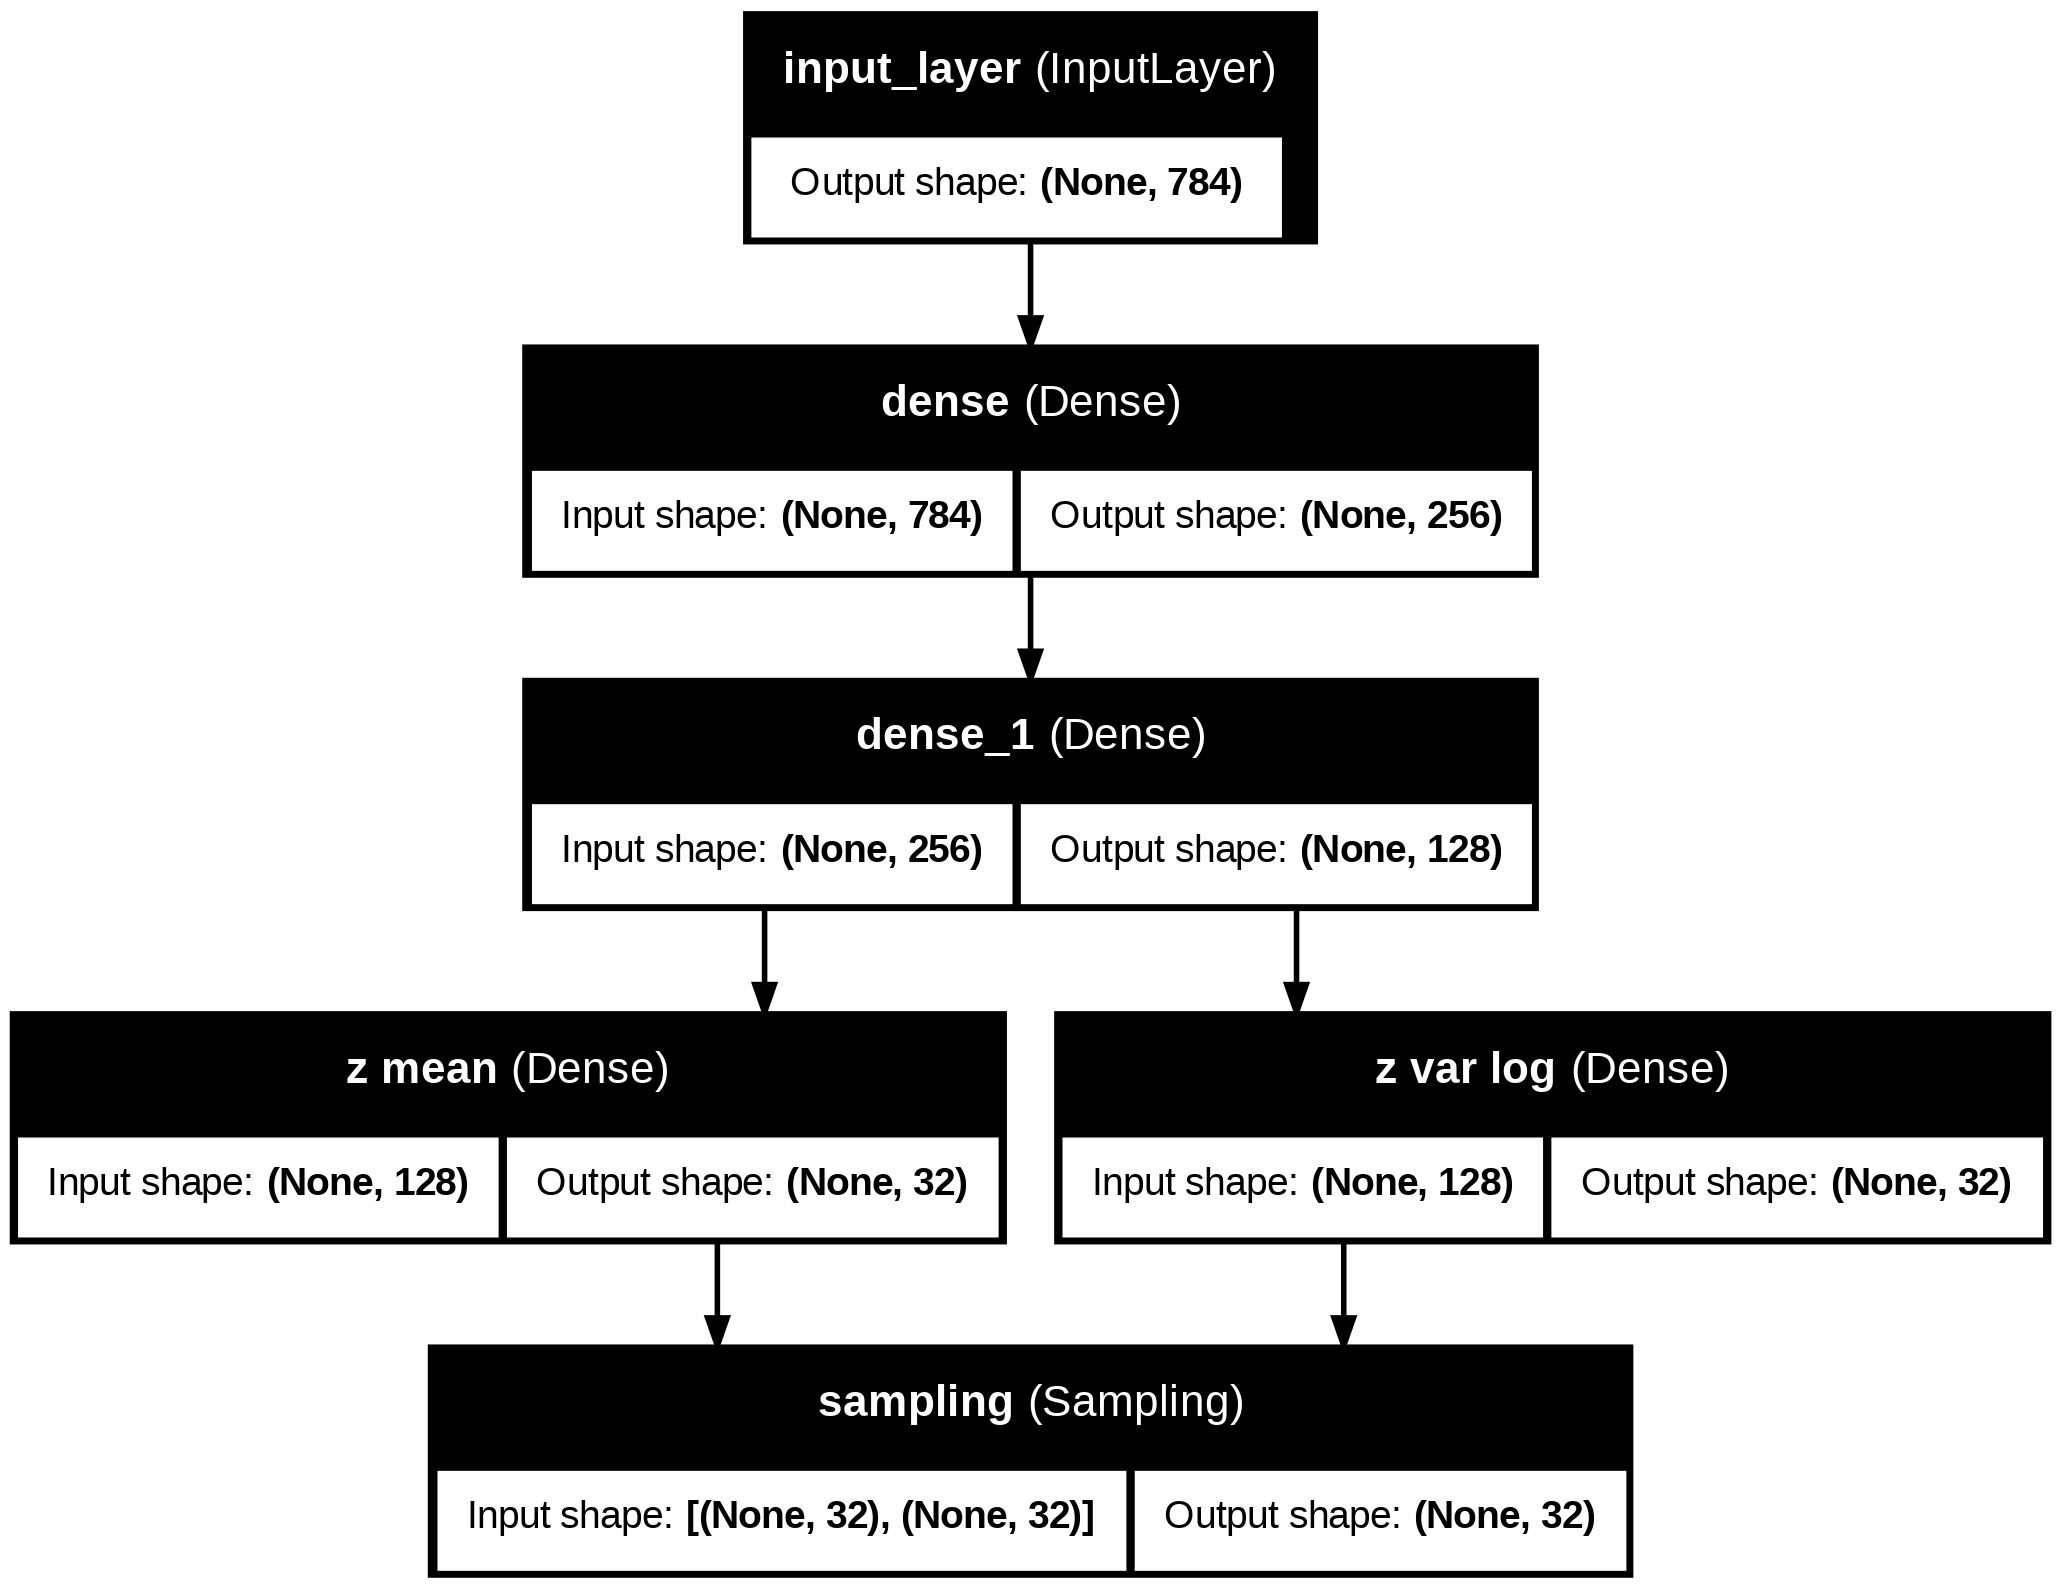

In [ ]:
keras.utils.plot_model(
    encoder,
    to_file="encoder.png",
    show_shapes=True,
    show_layer_names=True,
    show_dtype=False,
    expand_nested=True
)

In [ ]:
latent_inputs = keras.layers.Input(shape=(LATENT_DIM,), name='Latent')

x = keras.layers.Dense(
    units=128,
    activation='relu'
)(latent_inputs)
x = keras.layers.Dense(
    units=256,
    activation='relu'
)(x)
decoder_outputs = keras.layers.Dense(
    units=28*28,
    activation='sigmoid'
)(x)

decoder = keras.Model(
    latent_inputs,
    decoder_outputs,
    name='Decoder'
)

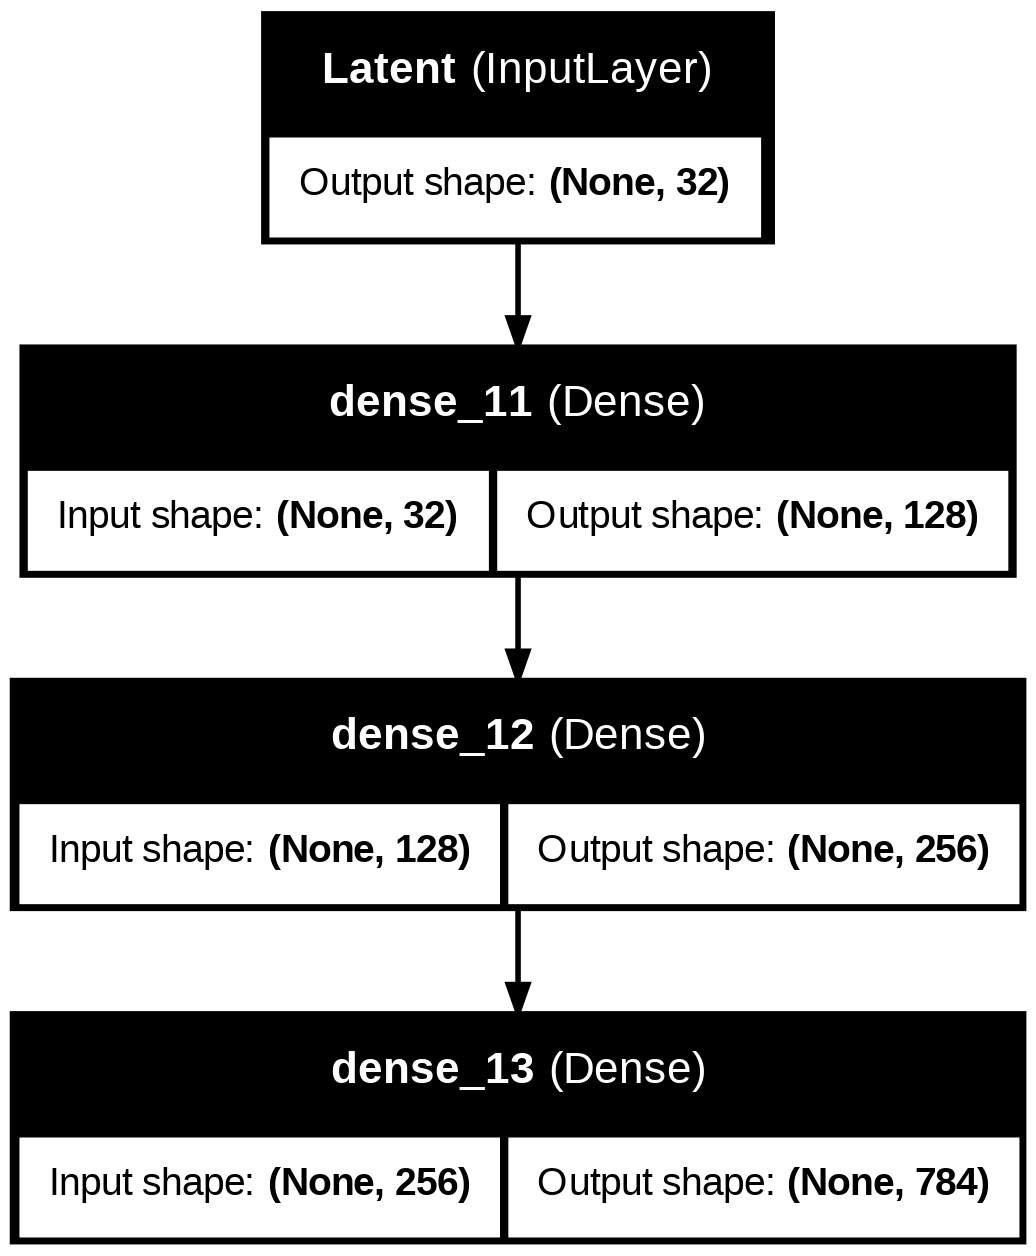

In [ ]:
keras.utils.plot_model(
    decoder,
    to_file="decoder.png",
    show_shapes=True,
    show_layer_names=True,
    show_dtype=False,
    expand_nested=True
)

binary cross entropy loss is actually

In [ ]:
from tensorflow import GradientTape

class VariationalAutoEncoder(keras.Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        return self.decoder(self.encoder)

    def train_epoch(self, data):
        if isinstance(data, tuple):
            # to avoid output
            data = data[0]

        with GradientTape() as tape:
            z_mean,